7.6
ARIMA forecasting
Max score: 1
Apply the ARIMA model to forecast future values of a real-world time series dataset.
Choose a time series dataset relevant to your field or interests (e.g., monthly sales, daily temperature, stock prices, website traffic).
Ensure the dataset has at least 200 observations and a clear temporal structure.
Handle missing values. Perform exploratory data analysis (EDA): visualize the time series, check for trends and seasonality. Test for stationarity using the Augmented Dickey-Fuller (ADF) test and apply differencing if necessary
Identify ARIMA parameters (p, d, q) using ACF and PACF plots or automated selection (e.g., auto_arima).Fit the ARIMA model to the training data.
Split the dataset into training and test sets. Forecast future values and compare predictions with actual test data. Report evaluation metrics such as RMSE, MAE, and MAPE.
Plot the original series, fitted values, and forecasted values.
Interpret the model parameters and results.


         Date  Temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8

Missing Values:
Date    0
Temp    0
dtype: int64



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\ROWTECH\AppData\Local\Temp\ipykernel_20408\480916044.py:39: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['Temp'] = df['Temp'].fillna(method='ffill')


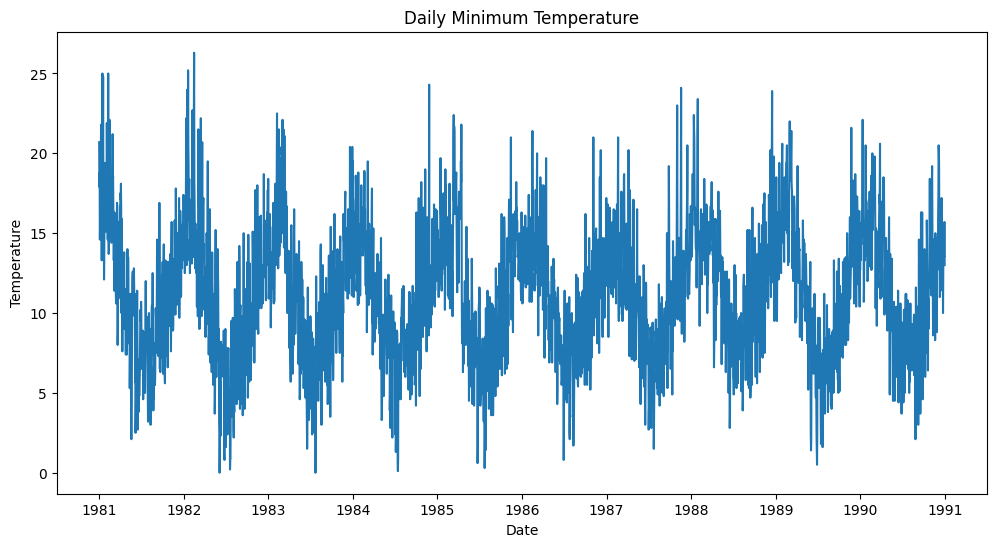


ADF Statistic: -4.444804924611687
p-value: 0.00024708263003611164
Series is stationary


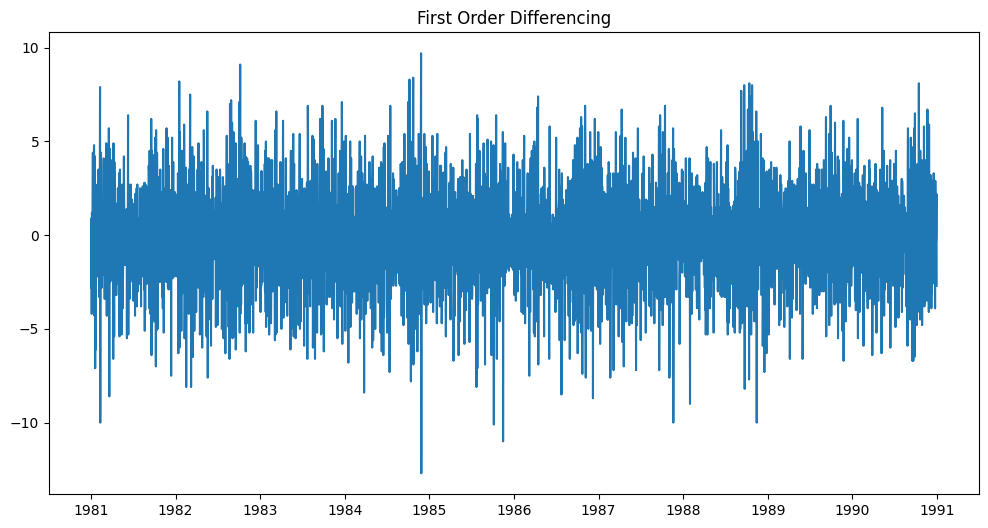


ADF After Differencing
ADF Statistic: -18.02822416799208
p-value: 2.6815618226750238e-30


<Figure size 1200x600 with 0 Axes>

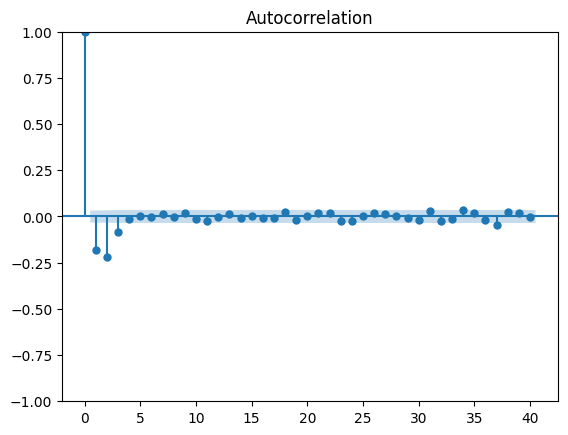

<Figure size 1200x600 with 0 Axes>

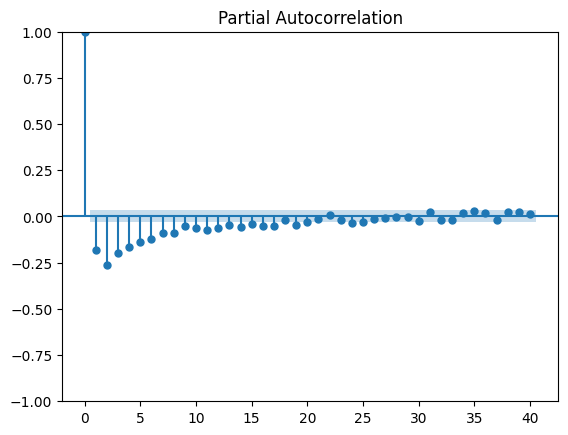


Training Size: 2920
Testing Size: 730


c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                   Temp   No. Observations:                 2920
Model:                 ARIMA(2, 1, 1)   Log Likelihood               -6765.575
Date:                Fri, 14 Aug 2026   AIC                          13539.150
Time:                        00:34:50   BIC                          13563.066
Sample:                             0   HQIC                         13547.764
                               - 2920                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4901      0.019     25.327      0.000       0.452       0.528
ar.L2         -0.1264      0.020     -6.452      0.000      -0.165      -0.088
ma.L1         -0.9027      0.011    -84.054      0.0

c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
C:\Users\ROWTECH\AppData\Local\Temp\ipykernel_20408\480916044.py:139: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  np.abs((test - forecast) / test)


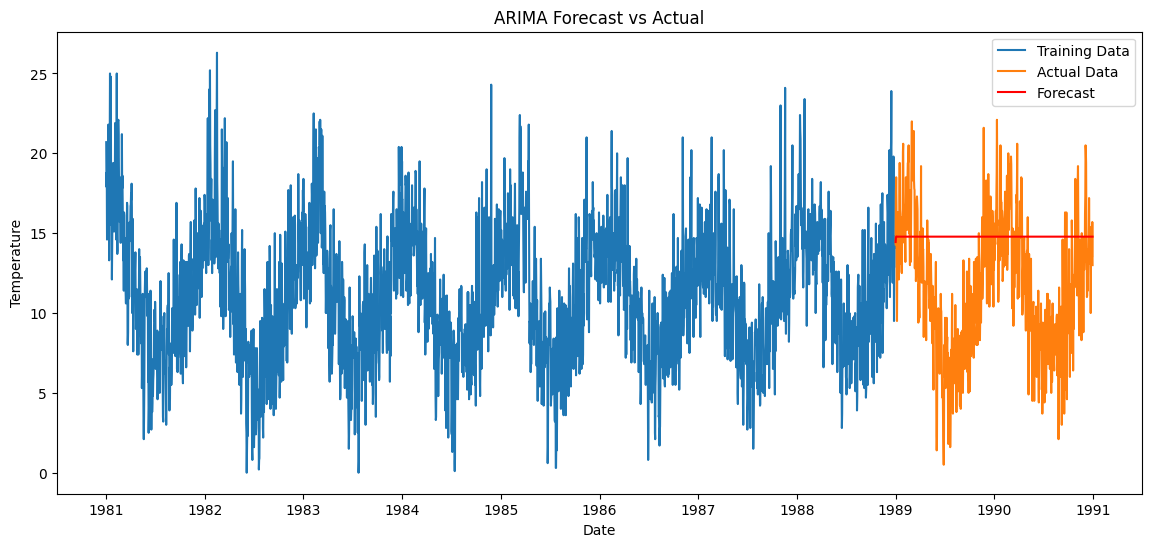

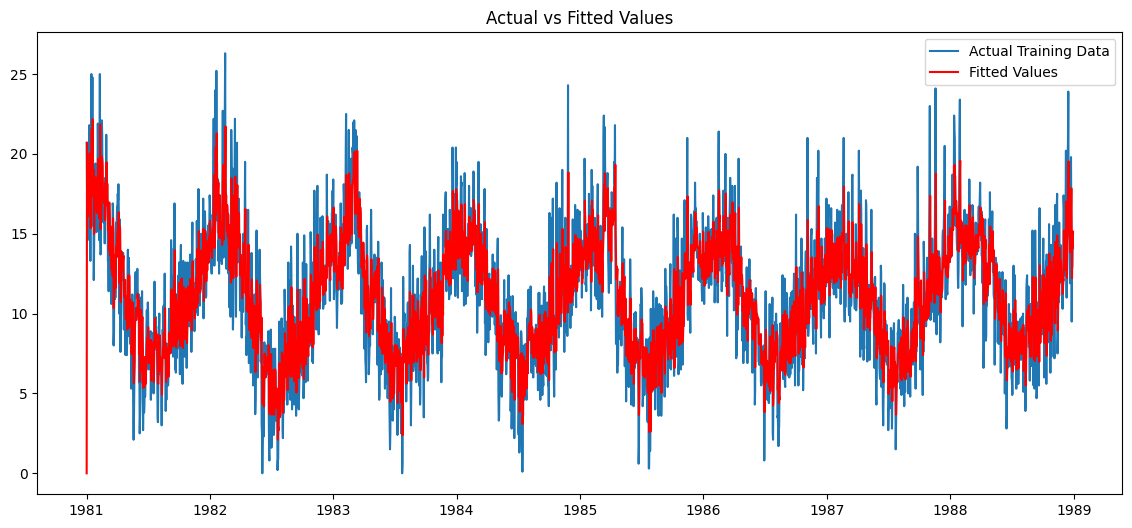


Future Forecasts:
2920    14.445752
2921    14.703702
2922    14.786400
2923    14.794313
2924    14.787735
2925    14.783511
2926    14.782273
2927    14.782200
2928    14.782321
2929    14.782389
2930    14.782407
2931    14.782408
2932    14.782405
2933    14.782404
2934    14.782404
2935    14.782404
2936    14.782404
2937    14.782404
2938    14.782404
2939    14.782404
2940    14.782404
2941    14.782404
2942    14.782404
2943    14.782404
2944    14.782404
2945    14.782404
2946    14.782404
2947    14.782404
2948    14.782404
2949    14.782404
Name: predicted_mean, dtype: float64


c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [3]:
# ==========================================
# ARIMA FORECASTING PROJECT
# Daily Minimum Temperature Dataset
# ==========================================


!pip install statsmodels

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

# ==========================================
# 1. Load Dataset
# ==========================================

df = pd.read_csv("daily-min-temperatures.csv")

print(df.head())

# ==========================================
# 2. Handle Missing Values
# ==========================================

print("\nMissing Values:")
print(df.isnull().sum())

df['Temp'] = df['Temp'].fillna(method='ffill')

# ==========================================
# 3. Convert Date Column
# ==========================================

df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

# ==========================================
# 4. Exploratory Data Analysis (EDA)
# ==========================================

plt.figure(figsize=(12,6))
plt.plot(df['Temp'])
plt.title("Daily Minimum Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.show()

# ==========================================
# 5. Augmented Dickey-Fuller Test
# ==========================================

result = adfuller(df['Temp'])

print('\nADF Statistic:', result[0])
print('p-value:', result[1])

if result[1] > 0.05:
    print("Series is NOT stationary")
else:
    print("Series is stationary")

# ==========================================
# 6. Differencing
# ==========================================

df_diff = df['Temp'].diff().dropna()

plt.figure(figsize=(12,6))
plt.plot(df_diff)
plt.title("First Order Differencing")
plt.show()

result2 = adfuller(df_diff)

print('\nADF After Differencing')
print('ADF Statistic:', result2[0])
print('p-value:', result2[1])

# ==========================================
# 7. ACF and PACF Plots
# ==========================================

plt.figure(figsize=(12,6))
plot_acf(df_diff, lags=40)
plt.show()

plt.figure(figsize=(12,6))
plot_pacf(df_diff, lags=40)
plt.show()

# ==========================================
# 8. Train Test Split
# ==========================================

train_size = int(len(df) * 0.8)

train = df['Temp'][:train_size]
test = df['Temp'][train_size:]

print("\nTraining Size:", len(train))
print("Testing Size:", len(test))

# ==========================================
# 9. Fit ARIMA Model
# ==========================================

# Example order chosen from ACF/PACF analysis
model = ARIMA(train, order=(2,1,1))

model_fit = model.fit()

print(model_fit.summary())

# ==========================================
# 10. Forecast
# ==========================================

forecast = model_fit.forecast(steps=len(test))

# ==========================================
# 11. Evaluation Metrics
# ==========================================

rmse = math.sqrt(mean_squared_error(test, forecast))
mae = mean_absolute_error(test, forecast)

mape = np.mean(
    np.abs((test - forecast) / test)
) * 100

print("\nEvaluation Metrics")
print("RMSE =", rmse)
print("MAE  =", mae)
print("MAPE =", mape)

# ==========================================
# 12. Plot Actual vs Forecast
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(train.index,
         train,
         label='Training Data')

plt.plot(test.index,
         test,
         label='Actual Data')

plt.plot(test.index,
         forecast,
         color='red',
         label='Forecast')

plt.title('ARIMA Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()

plt.show()

# ==========================================
# 13. Plot Fitted Values
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(train,
         label='Actual Training Data')

plt.plot(model_fit.fittedvalues,
         color='red',
         label='Fitted Values')

plt.title('Actual vs Fitted Values')
plt.legend()

plt.show()

# ==========================================
# 14. Forecast Future Values
# ==========================================

future_steps = 30

future_forecast = model_fit.forecast(
    steps=future_steps
)

print("\nFuture Forecasts:")
print(future_forecast)

# ==========================================
# END OF PROJECT
# ==========================================